# Publishing and Sharing

A chart or dashboard only creates value when the right people can see it, in the right format, with the right permissions, and without exposing data they must not see. This lesson covers export formats, sharing channels, version control of visual assets, and privacy checks before publishing.

**After this lesson you can:**

1. Choose between PNG, SVG, PDF and HTML exports, and set resolution correctly.
2. Choose a sharing channel and permission model for an audience.
3. Keep dashboards and charts under version control.
4. Protect privacy with aggregation and small-cell suppression before publishing.

**Data:** NYC yellow taxi trips, January 2024.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

import tempfile

OUT = Path(tempfile.mkdtemp())
trips = load_month("2024-01")

## 1. Export Formats

| Format | Type | Best for | Watch out |
| :--- | :--- | :--- | :--- |
| PNG | raster | slides, chat, e-mail, web | set `dpi` for the final size; no transparency on dark themes |
| SVG | vector | web pages, further editing | large for charts with many points |
| PDF | vector | print, reports | same as SVG |
| HTML | interactive | web, sharing explorations | needs a browser; may embed raw data |

The cell exports the same chart in several formats and compares sizes, once with 300 aggregated bars and once with 50,000 raw points.

In [2]:
daily = trips.groupby(trips["tpep_pickup_datetime"].dt.date).size()
sample = trips.sample(50_000, random_state=0)
rows = []
for name, draw in [("31 bars", lambda ax: ax.bar(daily.index, daily.values, color="#4E79A7")),
                   ("50,000 points", lambda ax: ax.scatter(sample["trip_distance"], sample["fare_amount"], s=1, alpha=0.3))]:
    for fmt, kw in [("png", {"dpi": 100}), ("png", {"dpi": 300}), ("svg", {}), ("pdf", {})]:
        fig, ax = plt.subplots(figsize=(6, 3.5))
        draw(ax)
        ax.set_title(name)
        path = OUT / f"{name.replace(',', '').replace(' ', '_')}_{kw.get('dpi', '')}.{fmt}"
        fig.savefig(path, facecolor="white", **kw)
        plt.close(fig)
        rows.append({"chart": name, "format": fmt + (f" @{kw['dpi']} dpi" if kw else ""), "KiB": round(path.stat().st_size / 1024, 1)})
sizes = pd.DataFrame(rows).pivot(index="format", columns="chart", values="KiB")
sizes

chart,31 bars,"50,000 points"
format,,
pdf,9.3,363.0
png @100 dpi,16.1,19.5
png @300 dpi,53.1,97.8
svg,28.4,7138.6


Vector formats are tiny for simple charts and huge for charts with many marks; raster formats have a size that depends on resolution, not on data. For a chart with thousands of points, use PNG (or rasterise the points layer with `rasterized=True` inside a PDF).

**Resolution:** a chart printed 15 cm wide at 300 dpi needs about 1,800 pixels in width. Set the figure size in inches to the final display size and choose `dpi`; do not scale a small image up.

## 2. Sharing Channels and Permissions

| Channel | Audience | Permissions | Cost |
| :--- | :--- | :--- | :--- |
| Tableau Public | anybody | public only | free |
| Power BI service / Tableau Cloud | colleagues | workspace and row-level security | licence |
| Apache Superset (self-hosted) | colleagues | roles, dataset permissions, row-level filters | free (your server) |
| Streamlit Community Cloud / HF Spaces | anybody or invited users | basic | free tier |
| GitHub Pages / Quarto site | anybody | public | free |
| PDF / PNG by e-mail | named people | none after sending | free |

Principles: share **links to a governed source** instead of copies, give the **least privilege** needed (view vs edit), and remember that an export or e-mail attachment escapes all access control.

## 3. Version Control for Visual Assets

Visual assets are code too:

| Tool | Text format for Git |
| :--- | :--- |
| Python charts, Streamlit apps | `.py` / `.ipynb` files |
| Tableau | `.twb` (XML) workbooks; `.twbx` are zipped with data, avoid in Git |
| Power BI | PBIP project format (folders with JSON/TMDL) instead of binary `.pbix` |
| Superset | dashboard export as a ZIP of YAML files (`superset export-dashboards`) |
| Vega-Lite / Plotly | JSON specs |

The cell saves an Altair chart specification as JSON and shows that a change appears as a readable diff.

In [3]:
import difflib
import json

import altair as alt

by_hour = trips.groupby(trips["tpep_pickup_datetime"].dt.hour).size().rename("trips").rename_axis("hour").reset_index()
v1 = alt.Chart(by_hour).mark_bar(color="#4E79A7").encode(x="hour:O", y="trips:Q").properties(title="Trips by hour")
v2 = alt.Chart(by_hour).mark_bar(color="#F28E2B").encode(x="hour:O", y="trips:Q").properties(title="Trips by hour of pickup")

def spec_lines(chart):
    spec = chart.to_dict()
    spec.pop("datasets", None)                                   # keep data out of the versioned spec
    return json.dumps(spec, indent=1, sort_keys=True).splitlines()

diff = [l for l in difflib.unified_diff(spec_lines(v1), spec_lines(v2), "v1.json", "v2.json", lineterm="") if l[:1] in "+-"]
print("\n".join(diff))

--- v1.json
+++ v2.json
-  "color": "#4E79A7",
+  "color": "#F28E2B",
- "title": "Trips by hour"
+ "title": "Trips by hour of pickup"


## 4. Privacy Before Publishing

Aggregated data can still reveal individuals when groups are **small**: a zone-hour cell with 2 trips may describe identifiable people. Common protections:

1. publish aggregates, not rows;
2. **suppress small cells** (for example, fewer than 10 trips) or merge them into "other";
3. coarsen detail (hour instead of minute, zone instead of address);
4. never publish free text or identifiers.

zone-day-hour cells: 73,171; cells with fewer than 10 trips: 41,940 (57%)
trips in suppressed cells: 98,009 (3.4% of all trips)


at zone-day level instead: 48% of cells are small


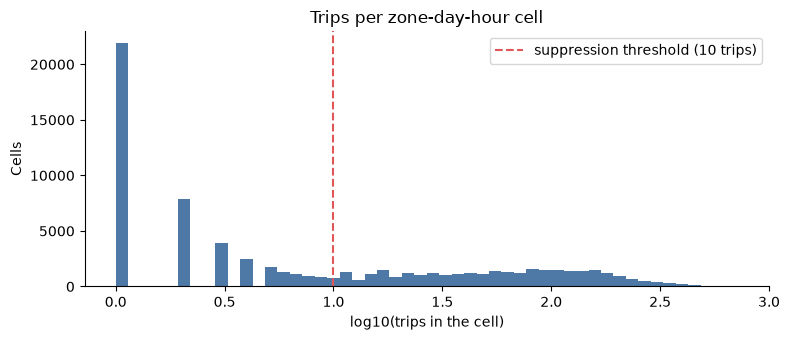

In [4]:
cells = trips.groupby(["PULocationID", trips["tpep_pickup_datetime"].dt.date, trips["tpep_pickup_datetime"].dt.hour]).size()
K = 10
small = cells[cells < K]
published = cells.where(cells >= K)                              # suppressed cells become missing
print(f"zone-day-hour cells: {len(cells):,}; cells with fewer than {K} trips: {len(small):,} ({len(small) / len(cells):.0%})")
print(f"trips in suppressed cells: {small.sum():,} ({small.sum() / cells.sum():.1%} of all trips)")
coarse = trips.groupby(["PULocationID", trips["tpep_pickup_datetime"].dt.date]).size()
print(f"at zone-day level instead: {(coarse < K).mean():.0%} of cells are small")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(cells), bins=50, color="#4E79A7")
ax.axvline(np.log10(K), color="#E15759", ls="--", label=f"suppression threshold ({K} trips)")
ax.set(title="Trips per zone-day-hour cell", xlabel="log10(trips in the cell)", ylabel="Cells")
ax.legend()
plt.tight_layout()
plt.show()

Many cells are small but contain only a small share of the trips: suppression protects privacy at a low cost in information. Coarsening to zone-day reduces the number of small cells further.

*Insight: Before you publish, decide the format by the medium, the channel by the audience, and the permissions by least privilege; keep visual assets in version control; and check aggregates for small cells that could identify people.*

## Real-World Use Case or Analogy

Publishing a dashboard is like **sending a letter**: choose the envelope (format), the address (audience), registered mail or a postcard (permissions), and do not write anything on a postcard that strangers must not read (privacy).

Statistics offices publish tables with small-cell suppression by law; companies have leaked customer data through dashboards shared as public links. A publishing checklist prevents both kinds of mistakes.